# ISM 6564 — Assignment 1

## A Tokenization Report

**Week 1 — Text as Data & Tokenization**

You are on the data platform team at an online retailer that also runs a large
public community forum. Three projects are blocked on one unmeasured decision:
how will we tokenize?

- **Project A — Lexical search.** An inverted index over the forum archive.
- **Project B — Thread summarization** through a frontier LLM API. Finance
  wants a cost number.
- **Project C — International rollout** to four more language markets on the same
  paid plan.

Work through Tasks 1–6. Read `README.md` first — it has the full task
descriptions, the deliverables, and the rubric. This notebook gives you the
data, the helpers, and the places to write your answers.

**Two rules that decide most of your mark:**

1. Every number you state in prose must be produced by a visible cell above it.
2. Run the whole notebook top to bottom before you submit. Outputs must be
   visible in the file you upload.

---

## Setup

Run this cell first. It is complete — nothing to fill in.

In [1]:
import os
import random
import re
import sys
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

# Portable device selection: CUDA, else Apple Silicon MPS, else CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

SEED = 6564
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print(f"python      {sys.version.split()[0]}")
print(f"torch       {torch.__version__}  (device: {device})")
print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")

python      3.12.14
torch       2.11.0+cpu  (device: cpu)
pandas      3.0.2
numpy       2.4.4


In [2]:
# Tokenizer libraries. All are already in the course environment.
import nltk
import tiktoken
from transformers import AutoTokenizer

# nltk.word_tokenize needs the Punkt sentence model. Downloaded once, cached.
for pkg in ("punkt", "punkt_tab"):
    try:
        nltk.data.find(f"tokenizers/{pkg}")
    except LookupError:
        nltk.download(pkg, quiet=True)

print("nltk       ", nltk.__version__)
print("tiktoken   ", tiktoken.__version__)
import transformers
print("transformers", transformers.__version__)

nltk        3.9.4
tiktoken    0.12.0
transformers 5.7.0


In [3]:
def todo(message):
    """Print a clear reminder instead of crashing on an unfinished TODO.

    Every task cell below starts with its answer variable set to None. Until
    you replace it, the cell prints this reminder and moves on, so the
    notebook always runs top to bottom.
    """
    print(f"[ TODO ]  {message}")


def show(obj, title=None):
    """Display a DataFrame or print anything else, with an optional heading."""
    if title:
        print(f"\n=== {title} ===")
    try:
        from IPython.display import display
        display(obj)
    except Exception:
        print(obj)

### The corpus

`load_corpus()` fetches four newsgroups from the 20 Newsgroups collection and
returns them as `(archive, holdout)`:

- **archive** — the train split. This is "the forum as it exists today". Every
  vocabulary you build comes from here.
- **holdout** — the test split. This is "next month's posts". You never fit
  anything on it; you only measure against it.

Headers and footers are stripped. Quoted reply text, signatures, e-mail
addresses, and URLs are **kept on purpose** — that surface noise is the whole
reason tokenization decisions matter.

scikit-learn downloads the collection once (~14 MB) and caches it in
`~/scikit_learn_data/`. After the first run you are offline.

In [4]:
from sklearn.datasets import fetch_20newsgroups

CATEGORIES = ["comp.sys.mac.hardware", "rec.sport.baseball", "sci.med", "sci.space"]


def load_corpus():
    """Return (archive_docs, holdout_docs) as lists of strings. Do not change."""
    kw = dict(categories=CATEGORIES, remove=("headers", "footers"),
              random_state=0, shuffle=False)
    archive = fetch_20newsgroups(subset="train", **kw).data
    holdout = fetch_20newsgroups(subset="test", **kw).data
    return archive, holdout


archive, holdout = load_corpus()

print(f"archive : {len(archive):>5,} documents  {sum(map(len, archive)):>10,} characters")
print(f"holdout : {len(holdout):>5,} documents  {sum(map(len, holdout)):>10,} characters")
print("\n--- a sample document ---")
print(archive[7][:600])

archive : 2,362 documents   3,133,653 characters
holdout : 1,572 documents   2,095,598 characters

--- a sample document ---
In article <1993Apr15.131954.1@fnalf.fnal.gov> higgins@fnalf.fnal.gov (Bill Higgins-- Beam Jockey) writes:

>Reid, alas, gives us no measure of the "power/influence" of readers...
>Sorry, Mark.

I think I can. Largely as a result of efforts by people reading this group
writing letters and making phone calls the following has happened:

1. NASA reprogrammed funds to keep NASP alive in 1991.
2. Efforts to kill DC-X and the SSRT progam where twice twarted
   (Feb. and June of last year).
3. Gouldin kept his job in spite of heavy lobbying against him.

This may not be what Mark was thinking of but


### The parallel multilingual corpus

`data/udhr_parallel.json` holds the Universal Declaration of Human Rights in
five languages: English, German, Spanish, Hindi, and Chinese (Simplified).
Every entry says **the same thing**, so any difference in token count is a
property of the tokenizer, not of the content. That is what makes it usable as
evidence rather than as illustration.

The five span the axes that matter here: Latin-script analytic (English),
Latin-script compounding (German), Latin-script inflecting (Spanish), a
Devanagari abugida (Hindi), and a logographic script with no whitespace word
boundaries (Chinese). Provenance is in `../data/README.md`.

In [5]:
import json
from urllib.request import urlopen

PARALLEL_URL = (
    "https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/"
    "week-01-text-tokenization/data/udhr_parallel.json"
)
PARALLEL_LOCAL = [
    Path("../data/udhr_parallel.json"),
    Path("week-01-text-tokenization/data/udhr_parallel.json"),
    Path("data/udhr_parallel.json"),
]


def load_parallel():
    """Local first so a clone works offline; URL fallback so Colab works."""
    raw = None
    for p in PARALLEL_LOCAL:
        if p.exists():
            raw = json.loads(p.read_text(encoding="utf-8"))
            break
    if raw is None:
        raw = json.loads(urlopen(PARALLEL_URL).read().decode("utf-8"))
    return pd.DataFrame([
        {"language": name, "code": d["code"], "script": d["script"],
         "n_chars": len(d["text"]), "text": d["text"]}
        for name, d in raw.items()
    ])


parallel = load_parallel()
show(parallel[["language", "code", "script", "n_chars"]], "parallel corpus")
print("\nEnglish, first 200 characters:")
print(parallel.loc[parallel.language == "English", "text"].iloc[0][:200])


=== parallel corpus ===


,language,code,script,n_chars
0,English,eng,Latin,10637
1,German,deu,Latin,11936
2,Spanish,spa,Latin,11964
3,Hindi,hin,Devanagari,11463
4,Chinese (Simplified),cmn-Hans,Han (Simplified),2988



English, first 200 characters:
Universal Declaration of Human Rights
Preamble
Whereas recognition of the inherent dignity and of the equal and inalienable rights of all members of the human family is the foundation of freedom, just


### The stress set and the rate card

`STRESS_SET` is eight short strings chosen to break things. `RATE_CARD` is an
**illustrative** price list in US dollars per million tokens — it is a stated
assumption of your analysis, not a quote from any vendor. Frontier pricing
changes often; if you use different numbers, say so and cite where they came
from.

In [6]:
STRESS_SET = [
    "Refund my order 😤 please",
    "café résumé naïve",
    "日本語のテキストです",
    "मानव अधिकारों की घोषणा",
    "Ωmega ΔV = 9.4 km/s",
    "₹1,299 refunded to ****4417",
    "https://forum.example.com/t/LC-475-won't-boot?ref=email",
    "🚀🛰️",
]

# Illustrative rate card: US dollars per 1,000,000 tokens.
RATE_CARD = {
    "input_per_mtok": 2.50,
    "output_per_mtok": 10.00,
}

for s in STRESS_SET:
    print(f"{len(s):>3} chars  {s}")
print()
print("RATE_CARD:", RATE_CARD)

 24 chars  Refund my order 😤 please
 17 chars  café résumé naïve
 10 chars  日本語のテキストです
 22 chars  मानव अधिकारों की घोषणा
 19 chars  Ωmega ΔV = 9.4 km/s
 27 chars  ₹1,299 refunded to ****4417
 55 chars  https://forum.example.com/t/LC-475-won't-boot?ref=email
  3 chars  🚀🛰️

RATE_CARD: {'input_per_mtok': 2.5, 'output_per_mtok': 10.0}


---

# Task 1 — Baseline: how many words are there?

Tokenize the **archive** three ways and compare. Then find three places where
whitespace splitting produces something that is not a word.

Full description and deliverables: `README.md`, Task 1.

In [ ]:
# ---------------------------------------------------------------- Task 1a
# A regex tokenizer.
#
# Design choice: a token is a run of letters/digits, and it may CONTAIN a
# single apostrophe or hyphen between two alphanumeric runs. So "won't" and
# "LC-475" stay whole, but a leading/trailing "-" or a bare "'" is left out,
# and every other punctuation mark drops out of the stream entirely.
# Consequence to defend: this shreds URLs and e-mail addresses into their
# alphanumeric pieces ("http", "a", "io", "x") -- acceptable here because a
# word index should not carry "http://a.io/x" as one term. Case is preserved,
# same as str.split and nltk.word_tokenize, so the three are compared on equal
# footing; case-folding is a separate normalization step.
import re

# [^\W_] matches any Unicode letter or number, excluding underscores
_TOKEN_RE = re.compile(r"[^\W_]+(?:['’\-][^\W_]+)*")

def regex_tokenize(text):
    """Tokenize `text` with a regular expression and return a list of strings."""
    return _TOKEN_RE.findall(text)

_probe = regex_tokenize("Don't ship the LC-475 -- it won't boot! see http://a.io/x café नमस्ते")
if _probe is None:
    todo("Task 1a - implement regex_tokenize()")
else:
    print(_probe)

["Don't", 'ship', 'the', 'LC-475', 'it', "won't", 'boot', 'see', 'http', 'a', 'io', 'x']


In [8]:
# ---------------------------------------------------------------- Task 1b
# The comparison table.
#
# Run each tokenizer over every document in `archive`, keep the full token
# stream (Task 2 and Task 3 reuse the whitespace one), and report the five
# summary statistics per tokenizer.

_tokenizers = {
    "whitespace": str.split,
    "regex": regex_tokenize,
    "nltk": nltk.word_tokenize,
}

streams = {
    name: [tok for doc in archive for tok in fn(doc)]
    for name, fn in _tokenizers.items()
}

task1_table = pd.DataFrame([
    {
        "tokenizer": name,
        "n_tokens": len(s),
        "n_types": len(set(s)),
        "type_token_ratio": len(set(s)) / len(s),
        "mean_tokens_per_doc": len(s) / len(archive),
    }
    for name, s in streams.items()
])

if streams is None or task1_table is None:
    todo("Task 1b - build `streams` and `task1_table`")
else:
    show(task1_table, "Task 1 - tokenizer comparison")



=== Task 1 - tokenizer comparison ===


,tokenizer,n_tokens,n_types,type_token_ratio,mean_tokens_per_doc
0,whitespace,501321,67367,0.134379,212.244285
1,regex,513526,40694,0.079244,217.411516
2,nltk,632239,42994,0.068003,267.671041


In [9]:
# ---------------------------------------------------------------- Task 1c
# The 15 most frequent types for each tokenizer, side by side.
# Each cell shows the type and its count so the differences are visible.

task1_top15 = pd.DataFrame({
    name: [f"{tok!r}  ({count:,})"
           for tok, count in Counter(s).most_common(15)]
    for name, s in streams.items()
})
task1_top15.index = range(1, 16)

if task1_top15 is None:
    todo("Task 1c - build `task1_top15`")
else:
    show(task1_top15, "Task 1 - 15 most frequent types")



=== Task 1 - 15 most frequent types ===


,whitespace,regex,nltk
1,"'the' (20,895)","'the' (21,228)","'.' (23,823)"
2,"'to' (11,027)","'to' (11,238)","',' (23,602)"
3,"'of' (10,302)","'a' (10,458)","'the' (21,214)"
4,"'a' (10,266)","'of' (10,455)","'>' (18,606)"
5,"'and' (9,098)","'and' (9,428)","'--' (11,418)"
6,"'in' (6,519)","'is' (6,769)","'to' (11,234)"
7,"'is' (6,475)","'in' (6,717)","'of' (10,450)"
8,"'I' (6,111)","'I' (6,702)","'a' (10,419)"
9,"'that' (5,274)","'that' (5,560)","'and' (9,392)"
10,"'>' (4,659)","'for' (4,451)","')' (8,107)"


In [10]:
# ---------------------------------------------------------------- Task 1d
# Three real failure cases, found by scanning `archive` in document order and
# taking the first whitespace token that matches each pattern:
#
#   1. an e-mail address glued into one token,
#   2. punctuation-glued text: a ">"-quoted word with trailing punctuation,
#   3. own choice: a slash-joined phrase wrapped in quotation marks.

_email_re = re.compile(r"^[\w.+-]+@[\w-]+\.[\w.-]+[\w]$")
_glue_re = re.compile(r"^>+[A-Za-z][A-Za-z]+[.,!?:;]$")
_own_re = re.compile(r'^"[A-Za-z]+/[A-Za-z]+"$')

_hits = {}
for _doc in archive:
    for _tok in _doc.split():
        if "email" not in _hits and _email_re.match(_tok):
            _hits["email"] = _tok
        elif "glue" not in _hits and _glue_re.match(_tok):
            _hits["glue"] = _tok
        elif "own" not in _hits and _own_re.match(_tok):
            _hits["own"] = _tok
    if len(_hits) == 3:
        break

failure_cases = [_hits["email"], _hits["glue"], _hits["own"]]

if failure_cases is None:
    todo("Task 1d - find three failure cases in `archive` and show all three tokenizations")
else:
    for s in failure_cases:
        print(repr(s))
        print("   split :", s.split())
        print("   regex :", regex_tokenize(s))
        print("   nltk  :", nltk.word_tokenize(s))
        print()


'gajarsky@pilot.njin.net'
   split : ['gajarsky@pilot.njin.net']
   regex : ['gajarsky', 'pilot', 'njin', 'net']
   nltk  : ['gajarsky', '@', 'pilot.njin.net']

'>history?'
   split : ['>history?']
   regex : ['history']
   nltk  : ['>', 'history', '?']

'"power/influence"'
   split : ['"power/influence"']
   regex : ['power', 'influence']
   nltk  : ['``', 'power/influence', "''"]



### Task 1 — write-up

The differences that change a search index decide **what counts as a term**. `str.split()` keeps `gajarsky@pilot.njin.net`, `>history?`, and `"power/influence"` as single tokens; regex and NLTK break each into its component words. A support agent searching the archive for `history` finds that post under regex or NLTK but not under whitespace, where the only index key is `>history?` — likewise `influence` inside `"power/influence"`, and any word inside an address. Whitespace also inflates the vocabulary — 67,367 types versus 40,694 for regex — almost entirely with punctuation-glued strings no one will query.

Cosmetic for search: whether `won't` stays whole or splits into `wo` + `n't`, whether `--` survives, and NLTK's `` `` `` / `''` quote symbols. Case-folding and internal hyphens (`LC-475`) matter only if the query path applies the identical rule — a normalization decision, not a tokenizer property.


---

# Task 2 — Vocabulary growth

Walk the archive in document order. Every 25,000 tokens, record how many
tokens you have seen and how many **distinct** types you have seen, for three
tokenizers: whitespace, `bert-base-uncased`, and `gpt2`.

Then fit Heaps' law to the whitespace curve:

$$V = k N^{\beta} \qquad\Longleftrightarrow\qquad \log V = \log k + \beta \log N$$

That second form is an ordinary least-squares line fit, which you have done
many times. `np.polyfit(log_N, log_V, 1)` returns $(\beta, \log k)$.

Full description and deliverables: `README.md`, Task 2.

In [11]:
# Loading the two Hugging Face tokenizers. Complete -- nothing to fill in.
# The first call downloads a few hundred KB and caches it in ~/.cache/huggingface.

bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
gpt2_tok = AutoTokenizer.from_pretrained("gpt2")

print(f"bert-base-uncased  vocab_size={bert_tok.vocab_size:,}  unk={bert_tok.unk_token!r}")
print(f"gpt2               vocab_size={gpt2_tok.vocab_size:,}  unk={gpt2_tok.unk_token!r}")
print()
sample = "The LC-475 won't boot after the 7.5.3 update — café included."
print("bert:", bert_tok.tokenize(sample))
print("gpt2:", gpt2_tok.tokenize(sample))

bert-base-uncased  vocab_size=30,522  unk='[UNK]'
gpt2               vocab_size=50,257  unk='<|endoftext|>'

bert: ['the', 'lc', '-', '475', 'won', "'", 't', 'boot', 'after', 'the', '7', '.', '5', '.', '3', 'update', '—', 'cafe', 'included', '.']
gpt2: ['The', 'ĠLC', '-', '475', 'Ġwon', "'t", 'Ġboot', 'Ġafter', 'Ġthe', 'Ġ7', '.', '5', '.', '3', 'Ġupdate', 'ĠâĢĶ', 'ĠcafÃ©', 'Ġincluded', '.']


In [12]:
# ---------------------------------------------------------------- Task 2a
# The three token streams over the archive, in document order.
#
# Whitespace: reuse the Task 1 stream.
# BERT / GPT-2: tokenize the whole document list at once, then flatten. We use
#   the integer id stream (not the surface pieces) -- ids are 1:1 with vocab
#   entries, so "distinct ids" == "distinct types" and it is faster to hash.
#   add_special_tokens=False keeps [CLS]/[SEP] out of the counts.
# The "sequence longer than model maximum" warning is about running the model,
# not the tokenizer; it is harmless here.

_bert_ids = bert_tok(archive, add_special_tokens=False)["input_ids"]
_gpt2_ids = gpt2_tok(archive, add_special_tokens=False)["input_ids"]

growth_streams = {
    "whitespace": streams["whitespace"],
    "bert": [i for doc in _bert_ids for i in doc],
    "gpt2": [i for doc in _gpt2_ids for i in doc],
}

if growth_streams is None:
    todo("Task 2a - build `growth_streams`")
else:
    for k, v in growth_streams.items():
        print(f"{k:<12} {len(v):>9,} tokens   {len(set(v)):>7,} distinct")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1107 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1177 > 1024). Running this sequence through the model will result in indexing errors


whitespace     501,321 tokens    67,367 distinct
bert           791,486 tokens    17,500 distinct
gpt2           916,109 tokens    28,852 distinct


In [13]:
# ---------------------------------------------------------------- Task 2b
# The growth curves. Walk each stream once, adding to a set as we go; record
# (tokens_seen, distinct_so_far) every CHECKPOINT tokens, plus a final point
# so the curve reaches the end of the stream.

CHECKPOINT = 25_000


def vocab_growth(stream, checkpoint=CHECKPOINT):
    seen = set()
    ns, vs = [], []
    for i, tok in enumerate(stream, start=1):
        seen.add(tok)
        if i % checkpoint == 0:
            ns.append(i)
            vs.append(len(seen))
    if not ns or ns[-1] != len(stream):
        ns.append(len(stream))
        vs.append(len(seen))
    return np.array(ns), np.array(vs)


growth_curves = {name: vocab_growth(s) for name, s in growth_streams.items()}

if growth_curves is None:
    todo("Task 2b - build `growth_curves`")
else:
    for name, (N, V) in growth_curves.items():
        print(f"{name:<12} {len(N):>3} checkpoints   final N={N[-1]:>9,}   final V={V[-1]:>7,}")


whitespace    21 checkpoints   final N=  501,321   final V= 67,367
bert          32 checkpoints   final N=  791,486   final V= 17,500
gpt2          37 checkpoints   final N=  916,109   final V= 28,852


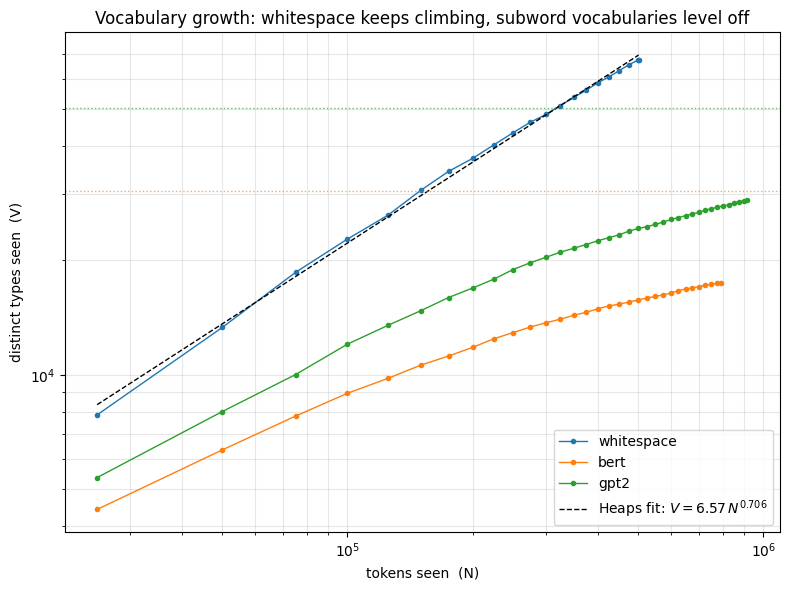

Heaps' law on the whitespace curve:  k = 6.565   beta = 0.7059


In [14]:
# ---------------------------------------------------------------- Task 2c
# Plot all three curves on log-log axes; fit Heaps' law to the whitespace
# curve only and overlay the fitted line.
#
#   log V = log k + beta * log N   ->   np.polyfit(log N, log V, 1) = (beta, log k)

N_ws, V_ws = growth_curves["whitespace"]
heaps_beta, _log_k = np.polyfit(np.log(N_ws), np.log(V_ws), 1)
heaps_k = float(np.exp(_log_k))
heaps_beta = float(heaps_beta)

if growth_curves is None:
    todo("Task 2c - needs `growth_curves` from 2b")
elif heaps_k is None:
    todo("Task 2c - fit Heaps' law and plot the three curves")
else:
    fig, ax = plt.subplots(figsize=(8, 6))
    _colors = {"whitespace": "C0", "bert": "C1", "gpt2": "C2"}
    for name, (N, V) in growth_curves.items():
        ax.loglog(N, V, marker="o", ms=3, lw=1, color=_colors[name], label=name)
    _fit = heaps_k * N_ws ** heaps_beta
    ax.loglog(N_ws, _fit, "--", color="k", lw=1,
              label=fr"Heaps fit: $V = {heaps_k:.2f}\,N^{{{heaps_beta:.3f}}}$")
    for name, tok in [("bert", bert_tok), ("gpt2", gpt2_tok)]:
        ax.axhline(tok.vocab_size, color=_colors[name], ls=":", lw=1, alpha=0.7)
    ax.set_xlabel("tokens seen  (N)")
    ax.set_ylabel("distinct types seen  (V)")
    ax.set_title("Vocabulary growth: whitespace keeps climbing, subword vocabularies level off")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"Heaps' law on the whitespace curve:  k = {heaps_k:.3f}   beta = {heaps_beta:.4f}")


### Task 2 — write-up

On log–log axes the whitespace curve is essentially a straight line: distinct types grow as a power law of tokens seen, $V \approx 6.57\,N^{0.706}$, with $\beta = 0.706 < 1$ but **no upper bound** — every new spelling, typo, address, or number is a new type.

The two subword curves start at the same slope, then bend over and flatten. BERT ends at 17,500 distinct pieces, GPT-2 at 28,852, each approaching its fixed vocabulary size (30,522 and 50,257).

That ceiling is a design decision, not a fact about this corpus. BERT and GPT-2 froze their vocabularies at training time; anything unseen is rebuilt from pieces already in the table instead of added as a new entry. A whitespace tokenizer has no table to freeze, so its $\beta$ never has to fall toward zero. Same text, different curve — one method admits new types, the other refuses to.


---

# Task 3 — Out of vocabulary

Three measurements that appear to contradict each other. Reconciling them is
the task.

Full description and deliverables: `README.md`, Task 3.

In [15]:
# ---------------------------------------------------------------- Task 3a
# Word-level OOV against the held-out split.
#
# Rank the archive's whitespace types by frequency. For each cap V keep the V
# most frequent (V=None keeps all), then measure on the held-out split:
#   oov_token_rate = held-out token OCCURRENCES not in vocab / held-out tokens
#   oov_type_rate  = held-out DISTINCT types not in vocab   / held-out types

VOCAB_CAPS = [2_000, 5_000, 10_000, 25_000, 50_000, None]

_archive_freq = Counter(streams["whitespace"])
_ranked_types = [tok for tok, _ in _archive_freq.most_common()]

_holdout_tokens = [tok for doc in holdout for tok in doc.split()]
_holdout_types = set(_holdout_tokens)
_n_holdout_tokens = len(_holdout_tokens)
_n_holdout_types = len(_holdout_types)

_rows = []
for cap in VOCAB_CAPS:
    vocab = set(_ranked_types) if cap is None else set(_ranked_types[:cap])
    n_oov_tokens = sum(1 for tok in _holdout_tokens if tok not in vocab)
    n_oov_types = len(_holdout_types - vocab)
    _rows.append({
        "vocab_cap": "all" if cap is None else cap,
        "vocab_size": len(vocab),
        "oov_token_rate": n_oov_tokens / _n_holdout_tokens,
        "oov_type_rate": n_oov_types / _n_holdout_types,
    })
oov_table = pd.DataFrame(_rows)

if oov_table is None:
    todo("Task 3a - build `oov_table`")
else:
    show(oov_table, "Task 3a - word-level OOV on held-out text")



=== Task 3a - word-level OOV on held-out text ===


,vocab_cap,vocab_size,oov_token_rate,oov_type_rate
0,2000,2000,0.333953,0.957983
1,5000,5000,0.254872,0.899235
2,10000,10000,0.202741,0.820602
3,25000,25000,0.153617,0.692857
4,50000,50000,0.127593,0.600055
5,all,67367,0.113678,0.547428


In [16]:
# ---------------------------------------------------------------- Task 3b
# How many [UNK] tokens do the subword tokenizers actually emit on the
# held-out split? Tokenize `holdout`, count the unk id, report count and rate.

_bert_hold = [i for doc in bert_tok(holdout, add_special_tokens=False)["input_ids"] for i in doc]
_gpt2_hold = [i for doc in gpt2_tok(holdout, add_special_tokens=False)["input_ids"] for i in doc]

unk_counts = {
    "bert": (sum(1 for i in _bert_hold if i == bert_tok.unk_token_id), len(_bert_hold)),
    "gpt2": (sum(1 for i in _gpt2_hold if i == gpt2_tok.unk_token_id), len(_gpt2_hold)),
}

if unk_counts is None:
    todo("Task 3b - count [UNK] tokens on the held-out split")
else:
    for name, (n_unk, n_tok) in unk_counts.items():
        print(f"{name:<6} {n_unk:>8,} UNK / {n_tok:>9,} tokens = {n_unk / n_tok:.6%}")


bert          0 UNK /   517,522 tokens = 0.000000%
gpt2          0 UNK /   614,397 tokens = 0.000000%


In [17]:
# ---------------------------------------------------------------- Task 3c
# The stress set. For each string and each of bert_tok / gpt2_tok report the
# token list, the [UNK] count, and whether decode(encode(s)) == s.
# add_special_tokens=False so [CLS]/[SEP] do not break the round-trip equality.

def _profile(s, tok):
    ids = tok.encode(s, add_special_tokens=False)
    pieces = tok.convert_ids_to_tokens(ids)
    return {
        "string": s,
        "tokenizer": "bert" if tok is bert_tok else "gpt2",
        "n_tokens": len(ids),
        "n_unk": sum(1 for i in ids if i == tok.unk_token_id),
        "roundtrip_ok": tok.decode(ids) == s,
        "tokens": pieces,
    }

stress_table = pd.DataFrame(
    [_profile(s, t) for s in STRESS_SET for t in (bert_tok, gpt2_tok)]
)

if stress_table is None:
    todo("Task 3c - build `stress_table`")
else:
    show(stress_table, "Task 3c - stress set")



=== Task 3c - stress set ===


,string,tokenizer,n_tokens,n_unk,roundtrip_ok,tokens
0,Refund my order 😤 please,bert,6,1,False,"[ref, ##und, my, order, [UNK], please]"
1,Refund my order 😤 please,gpt2,7,0,True,"[Ref, und, Ġmy, Ġorder, ĠðŁĺ, ¤, Ġplease]"
2,café résumé naïve,bert,3,0,False,"[cafe, resume, naive]"
3,café résumé naïve,gpt2,7,0,True,"[c, af, Ã©, ĠrÃ©, sum, Ã©, ĠnaÃ¯ve]"
4,日本語のテキストです,bert,10,0,False,"[日, 本, 語, の, ##テ, ##キ, ##ス, ##ト, ##て, ##す]"
5,日本語のテキストです,gpt2,12,0,True,"[æĹ, ¥, æľ, ¬, èª, ŀ, ãģ®, ãĥĨ, ãĤŃ, ãĤ¹ãĥĪ, ã..."
6,मानव अधिकारों की घोषणा,bert,14,1,False,"[म, ##ा, ##न, ##व, अ, ##ध, ##ि, ##क, ##ा, ##र,..."
7,मानव अधिकारों की घोषणा,gpt2,35,0,True,"[à¤, ®, à¤¾, à¤, ¨, à¤, µ, Ġà¤, ħ, à¤, §, à¤, ..."
8,Ωmega ΔV = 9.4 km/s,bert,12,0,False,"[ω, ##me, ##ga, δ, ##v, =, 9, ., 4, km, /, s]"
9,Ωmega ΔV = 9.4 km/s,gpt2,12,0,True,"[Î, ©, mega, ĠÎĶ, V, Ġ=, Ġ9, ., 4, Ġkm, /, s]"


### Task 3 — write-up

Part B and Part C look contradictory: on the held-out split BERT and GPT-2 each emit **0 `[UNK]`**, yet on the eight stress strings BERT emits `[UNK]` on three and round-trips **none**. Both are real; the difference is the input distribution. The held-out split is the same English newsgroups as the archive, so every character BERT's WordPiece vocabulary needs is present. The stress set is built to sit outside that distribution: emoji and Devanagari are characters the vocabulary does not contain, so BERT falls back to `[UNK]`. GPT-2's byte-level BPE has no such failure mode — every byte encodes — so its `[UNK]` count is 0 everywhere. That is not the same as lossless: BERT still lowercases and strips accents, which is why it round-trips 0/8.

For Project A, the Part A word-level OOV table describes the real risk. A lexical index is built from whole words, and even with the full archive vocabulary, 11.4% of held-out token occurrences and 54.7% of held-out types are missing — queries that return nothing. The Part B `[UNK]` count (~0) is not the relevant number: you would not index WordPiece fragments, and a zero on English says nothing about the non-English traffic Project C adds.


---

# Task 4 — Reversibility and normalization

Two questions a pipeline must answer before it processes a single document:
can I get my text back, and which Unicode form am I storing?

Full description and deliverables: `README.md`, Task 4.

In [18]:
# Complete -- nothing to fill in. cl100k_base is the encoding behind the
# GPT-4-class models; o200k_base is the newer one. Both are byte-level BPE.

enc_cl100k = tiktoken.get_encoding("cl100k_base")
enc_o200k = tiktoken.get_encoding("o200k_base")

print("cl100k_base  n_vocab =", enc_cl100k.n_vocab)
print("o200k_base   n_vocab =", enc_o200k.n_vocab)
print()
print("tokens of ' strawberry' under cl100k_base:",
      [enc_cl100k.decode([t]) for t in enc_cl100k.encode(" strawberry")])

cl100k_base  n_vocab = 100277
o200k_base   n_vocab = 200019

tokens of ' strawberry' under cl100k_base: [' strawberry']


In [19]:
# ---------------------------------------------------------------- Task 4a
# Round-trip six strings through three tokenizers. Includes an accented word
# and an emoji. Where the round trip fails, print what came back.

roundtrip_strings = [
    "café",                 # precomposed accent
    "naïve résumé",         # two accented words
    "🚀 to the moon",        # emoji + ASCII
    "LC-475 won't boot",    # SKU, hyphen, contraction
    "日本語",                # CJK
    "₹1,299",               # currency symbol + digits
]

def _roundtrips(s):
    out = {"string": s}
    # BERT / GPT-2: HF tokenizers, no special tokens so equality is fair.
    for label, tok in [("bert", bert_tok), ("gpt2", gpt2_tok)]:
        back = tok.decode(tok.encode(s, add_special_tokens=False))
        out[label] = back == s
        if back != s:
            print(f"  {label:<12} {s!r:<24} -> {back!r}")
    # tiktoken cl100k_base
    back = enc_cl100k.decode(enc_cl100k.encode(s))
    out["cl100k_base"] = back == s
    if back != s:
        print(f"  {'cl100k_base':<12} {s!r:<24} -> {back!r}")
    return out

roundtrip_table = pd.DataFrame([_roundtrips(s) for s in roundtrip_strings])

if roundtrip_table is None:
    todo("Task 4a - build `roundtrip_strings` and `roundtrip_table`")
else:
    show(roundtrip_table, "Task 4a - decode(encode(s)) == s ?")


  bert         'café'                   -> 'cafe'
  bert         'naïve résumé'           -> 'naive resume'
  bert         '🚀 to the moon'          -> '[UNK] to the moon'
  bert         "LC-475 won't boot"      -> "lc - 475 won ' t boot"
  bert         '日本語'                    -> '日 本 語'
  bert         '₹1,299'                 -> '₹1, 299'

=== Task 4a - decode(encode(s)) == s ? ===


,string,bert,gpt2,cl100k_base
0,café,False,True,True
1,naïve résumé,False,True,True
2,🚀 to the moon,False,True,True
3,LC-475 won't boot,False,True,True
4,日本語,False,True,True
5,"₹1,299",False,True,True


In [20]:
# ---------------------------------------------------------------- Task 4b
# The composed / decomposed trap. Same three visible characters, two byte
# sequences, two Python strings. Report the token count of each form under
# all four tokenizers.

nfc = unicodedata.normalize("NFC", "café")
nfd = unicodedata.normalize("NFD", "café")
print(f"NFC: {len(nfc)} code points {[hex(ord(c)) for c in nfc]}")
print(f"NFD: {len(nfd)} code points {[hex(ord(c)) for c in nfd]}")
print(f"nfc == nfd ? {nfc == nfd}")
print()

_counters = {
    "bert": lambda s: len(bert_tok.encode(s, add_special_tokens=False)),
    "gpt2": lambda s: len(gpt2_tok.encode(s)),
    "cl100k_base": lambda s: len(enc_cl100k.encode(s)),
    "o200k_base": lambda s: len(enc_o200k.encode(s)),
}

norm_table = pd.DataFrame(
    {"NFC": {k: fn(nfc) for k, fn in _counters.items()},
     "NFD": {k: fn(nfd) for k, fn in _counters.items()}}
).T
norm_table.index.name = "form"

if norm_table is None:
    todo("Task 4b - build `norm_table`")
else:
    show(norm_table, "Task 4b - token counts, NFC vs NFD")


NFC: 4 code points ['0x63', '0x61', '0x66', '0xe9']
NFD: 5 code points ['0x63', '0x61', '0x66', '0x65', '0x301']
nfc == nfd ? False


=== Task 4b - token counts, NFC vs NFD ===


,bert,gpt2,cl100k_base,o200k_base
form,,,,
NFC,1,3,2,2
NFD,1,4,3,3


### Task 4 — normalization policy

**Policy.** Normalize every string to **NFC** at ingest — immediately after decoding bytes to text, before anything is stored, indexed, or token-counted — and apply the same NFC step to every query string.

Why, from the numbers: NFC `café` and NFD `café` are unequal Python strings that hash differently and tokenize to different lengths (gpt2 3 vs 4, cl100k_base 2 vs 3, o200k_base 2 vs 3). Without one canonical form, identical content silently misses in the index, defeats deduplication, and produces two different token bills. Normalizing once at the boundary prevents all three.


---

# Task 5 — Token cost, and who pays it

Tokens are the unit of API billing and the unit of the context window. This
task turns your token counts into dollars, then asks who those dollars fall on.

Full description and deliverables: `README.md`, Task 5.

In [21]:
# ---------------------------------------------------------------- Task 5a
# Total tokens for the whole archive under both tiktoken encodings, then the
# monthly cost of Project B.
#
# Stated assumptions (kept as the notebook proposes them):
#   * one summarization pass over the whole archive per month
#   * output tokens = 15% of input tokens
#   * prices from RATE_CARD ($ per 1,000,000 tokens)
# Arithmetic per encoding:
#   input_cost  = input_tokens  / 1e6 * input_per_mtok
#   output_cost = output_tokens / 1e6 * output_per_mtok   (output = 0.15 * input)

OUTPUT_RATIO = 0.15

_rows = []
for name, enc in [("cl100k_base", enc_cl100k), ("o200k_base", enc_o200k)]:
    input_tokens = sum(len(x) for x in enc.encode_ordinary_batch(archive))
    output_tokens = input_tokens * OUTPUT_RATIO
    input_cost = input_tokens / 1e6 * RATE_CARD["input_per_mtok"]
    output_cost = output_tokens / 1e6 * RATE_CARD["output_per_mtok"]
    _rows.append({
        "encoding": name,
        "input_tokens": input_tokens,
        "output_tokens": round(output_tokens),
        "input_cost_usd": round(input_cost, 4),
        "output_cost_usd": round(output_cost, 4),
        "monthly_cost_usd": round(input_cost + output_cost, 4),
    })
archive_cost = pd.DataFrame(_rows)

if archive_cost is None:
    todo("Task 5a - compute archive token totals and monthly cost")
else:
    for r in _rows:
        print(f"{r['encoding']:<12} "
              f"{r['input_tokens']:>9,} in  x ${RATE_CARD['input_per_mtok']}/Mtok = ${r['input_cost_usd']:.4f}   "
              f"+ {r['output_tokens']:>8,} out x ${RATE_CARD['output_per_mtok']}/Mtok = ${r['output_cost_usd']:.4f}   "
              f"=> ${r['monthly_cost_usd']:.4f}/month")
    show(archive_cost, "Task 5a - monthly cost of Project B")


cl100k_base    808,286 in  x $2.5/Mtok = $2.0207   +  121,243 out x $10.0/Mtok = $1.2124   => $3.2331/month
o200k_base     797,999 in  x $2.5/Mtok = $1.9950   +  119,700 out x $10.0/Mtok = $1.1970   => $3.1920/month

=== Task 5a - monthly cost of Project B ===


,encoding,input_tokens,output_tokens,input_cost_usd,output_cost_usd,monthly_cost_usd
0,cl100k_base,808286,121243,2.0207,1.2124,3.2331
1,o200k_base,797999,119700,1.9950,1.1970,3.1920


In [22]:
# ---------------------------------------------------------------- Task 5b
# The same declaration in five languages. For each row of `parallel` and each
# encoding: n_chars, n_tokens, tokens_per_char, tokens_vs_english.
# English is 1.00 by construction (same encoding in numerator and denominator).

_encs = {"cl100k": enc_cl100k, "o200k": enc_o200k}
_en_text = parallel.loc[parallel.language == "English", "text"].iloc[0]
_en_tokens = {name: len(enc.encode(_en_text)) for name, enc in _encs.items()}

_rows = []
for _, r in parallel.iterrows():
    row = {"language": r.language, "script": r.script, "n_chars": r.n_chars}
    for name, enc in _encs.items():
        nt = len(enc.encode(r.text))
        row[f"{name}_tokens"] = nt
        row[f"{name}_tok_per_char"] = round(nt / r.n_chars, 4)
        row[f"{name}_vs_en"] = round(nt / _en_tokens[name], 3)
    _rows.append(row)
lang_table = pd.DataFrame(_rows)

if lang_table is None:
    todo("Task 5b - build `lang_table`")
else:
    show(lang_table, "Task 5b - tokens for identical content across languages")



=== Task 5b - tokens for identical content across languages ===


,language,script,n_chars,cl100k_tokens,cl100k_tok_per_char,cl100k_vs_en,o200k_tokens,o200k_tok_per_char,o200k_vs_en
0,English,Latin,10637,2016,0.1895,1.000,2017,0.1896,1.000
1,German,Latin,11936,3295,0.2761,1.634,2551,0.2137,1.265
2,Spanish,Latin,11964,2989,0.2498,1.483,2474,0.2068,1.227
3,Hindi,Devanagari,11463,11228,0.9795,5.569,3368,0.2938,1.670
4,Chinese (Simplified),Han (Simplified),2988,3451,1.1550,1.712,2367,0.7922,1.174


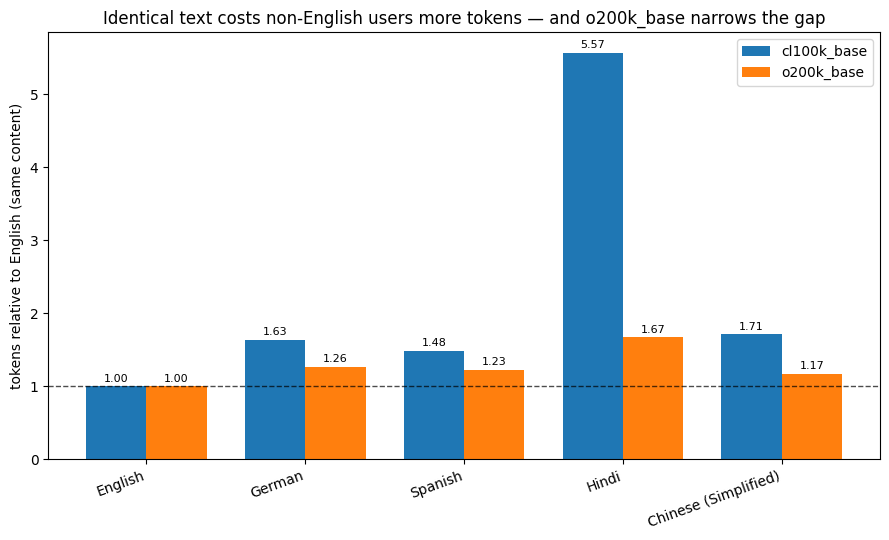

In [23]:
# ---------------------------------------------------------------- Task 5c
# tokens_vs_english per language, the two encodings side by side, English
# leftmost, a reference line at 1.0.

if lang_table is None:
    todo("Task 5c - needs `lang_table` from 5b")
else:
    _order = ["English", "German", "Spanish", "Hindi", "Chinese (Simplified)"]
    _df = lang_table.set_index("language").loc[_order]
    x = np.arange(len(_order))
    w = 0.38
    fig, ax = plt.subplots(figsize=(9, 5.5))
    b1 = ax.bar(x - w / 2, _df["cl100k_vs_en"], w, label="cl100k_base", color="C0")
    b2 = ax.bar(x + w / 2, _df["o200k_vs_en"], w, label="o200k_base", color="C1")
    ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=8)
    ax.axhline(1.0, color="k", lw=1, ls="--", alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(_order, rotation=20, ha="right")
    ax.set_ylabel("tokens relative to English (same content)")
    ax.set_title("Identical text costs non-English users more tokens — and o200k_base narrows the gap")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [24]:
# ---------------------------------------------------------------- Task 5d
# Convert the ratios into money. One English support conversation is fixed at
# 2,000 input + 500 output tokens. The same conversation in another language
# is assumed to scale BOTH counts by that language's tokens_vs_english ratio
# (Task 5b), under the same encoding.

EN_INPUT_TOKENS = 2_000
EN_OUTPUT_TOKENS = 500

def _conv_cost(in_tok, out_tok):
    return in_tok / 1e6 * RATE_CARD["input_per_mtok"] + out_tok / 1e6 * RATE_CARD["output_per_mtok"]

_rows = []
for _, r in lang_table.iterrows():
    row = {"language": r.language}
    for name in ("cl100k", "o200k"):
        ratio = r[f"{name}_vs_en"]
        row[f"{name}_cost_usd"] = round(_conv_cost(EN_INPUT_TOKENS * ratio,
                                                   EN_OUTPUT_TOKENS * ratio), 5)
    _rows.append(row)
conversation_cost = pd.DataFrame(_rows)
for name in ("cl100k", "o200k"):
    c = conversation_cost[f"{name}_cost_usd"]
    conversation_cost[f"{name}_vs_en"] = (c / c.iloc[0]).round(3)

if conversation_cost is None:
    todo("Task 5d - build `conversation_cost`")
else:
    show(conversation_cost, "Task 5d - cost of one support conversation, by language")
    for name in ("cl100k", "o200k"):
        c = conversation_cost[f"{name}_cost_usd"]
        hi, lo = conversation_cost.language[c.idxmax()], conversation_cost.language[c.idxmin()]
        print(f"{name:<7} most/least expensive ratio = {c.max() / c.min():.2f}  "
              f"({hi} ${c.max():.5f}  vs  {lo} ${c.min():.5f})")



=== Task 5d - cost of one support conversation, by language ===


,language,cl100k_cost_usd,o200k_cost_usd,cl100k_vs_en,o200k_vs_en
0,English,0.01000,0.01000,1.000,1.000
1,German,0.01634,0.01265,1.634,1.265
2,Spanish,0.01483,0.01227,1.483,1.227
3,Hindi,0.05569,0.01670,5.569,1.670
4,Chinese (Simplified),0.01712,0.01174,1.712,1.174


cl100k  most/least expensive ratio = 5.57  (Hindi $0.05569  vs  English $0.01000)
o200k   most/least expensive ratio = 1.67  (Hindi $0.01670  vs  English $0.01000)


### Task 5 — write-up

The users worst off are **Hindi (Devanagari) speakers**. For the identical declaration, `cl100k_base` charges them **5.57× as many tokens as English** (0.979 tokens/char vs 0.190). On the fixed 2,000 + 500-token conversation that is **\$0.0557 vs \$0.0100** — the same support interaction costs a Hindi speaker 5.6× what it costs an English speaker. Chinese is next at 1.71×, German 1.63×, Spanish 1.48×.

`o200k_base` changes this substantially. Hindi falls from 5.57× to **1.67×**, Chinese to 1.17×, German to 1.26×; the spread between most and least expensive language drops from 5.57 to 1.67. The newer encoding has a larger vocabulary (≈200k vs 100k) with far better non-Latin coverage, so Devanagari and Han text is carried in multi-character pieces instead of near one-token-per-character. The archive bill (Project B) barely moves — \$3.23 → \$3.19/month — because the archive is English; the encoding choice matters for users, not for this corpus.

Product's question: **no.** "The same paid plan" does not deliver the same product. Under `cl100k_base` a Hindi speaker gets 5.6× less content per dollar and reaches the context limit 5.6× sooner for identical information. `o200k_base` narrows that to ~1.7× — smaller, still not equal.


---

# Task 6 — Recommendation

**To:** Platform lead **From:** Data platform team
**Re:** How we tokenize — Projects A, B, and C

We measured three tokenization families against the forum archive (2,362 documents) and its held-out month (1,572 documents), plus a five-language parallel corpus. The finding is not "which tokenizer is best." It is that the three projects have different failure modes and should not share one answer. Below is a recommendation for each, the number behind it, and what we still do not know.

**Project A — lexical search.** Use a rule-based word tokenizer (our regex, or NLTK's Penn Treebank), applied identically at index time and query time, with Unicode NFC normalization and case-folding. Not `str.split()`, and not subword pieces. Whitespace splitting keeps `gajarsky@pilot.njin.net`, `>history?`, and `"power/influence"` as single index keys, so a search for `history` or `influence` returns nothing; it also inflates the vocabulary to 67,367 types against 40,694 for the regex, nearly all punctuation-glued junk. Plan around this: even the full-vocabulary word index leaves 11.4% of held-out token occurrences and 54.7% of held-out types unindexed. That gap — not the ~0% `[UNK]` rate the subword tokenizers report on English — is the coverage risk.

**Project B — thread summarization.** Adopt a model on the `o200k_base` encoding and budget from its counts. Under the stated assumptions (one pass per month, output at 15% of input, the illustrative rate card), the archive costs **\$3.19/month** on `o200k_base` versus **\$3.23/month** on `cl100k_base`. The encoding choice is nearly free for this English corpus; the reason to prefer `o200k_base` is Project C. Re-run the figure against real monthly thread volume before signing anything.

**Project C — international rollout.** "The same paid plan" is not the same product, and we should say so in writing. On identical content, `cl100k_base` bills a Hindi speaker **5.57×** the tokens of an English speaker (Chinese 1.71×, German 1.63×); one fixed support conversation costs **\$0.0557 vs \$0.0100**. Moving to `o200k_base` cuts the Hindi penalty to **1.67×** and the worst-case spread from 5.57 to 1.67. Launch on `o200k_base`, and set per-market cost and context-window budgets from the Task 5b ratios rather than assuming parity.

**Measure before committing.** The parallel corpus is UDHR legal prose; real forum posts (code blocks, SKUs, quoted replies, emoji) tokenize differently. Tokenize a real sample of 1,000+ posts per target language and recompute the per-language ratio. Decision rule: if any market's measured ratio on real text exceeds **2.0× English under `o200k_base`**, that market gets its own budget line and a product decision on message-length limits — not the shared plan.

**One cross-tokenizer risk.** If text is length-trimmed with one tokenizer and then sent to a model trained on another, budgets and offsets are wrong: a 4,000-`cl100k`-token prompt trimmed "to fit" can overflow or under-fill an `o200k` context, and character offsets used for highlighting land in the wrong place. Control: never hand-roll token math. Build the tokenizer from the model identifier in one factory function, assert its encoding name equals the model's expected encoding at startup, and pin both in one config object so they cannot drift apart.

**What this analysis does not establish.** It does not tell us whether any of these tokenizers produce good summaries, good search ranking, or acceptable latency — we measured token counts, vocabulary growth, OOV, and reversibility, not output quality. It rests on one small corpus of 1990s English newsgroup text, an illustrative rate card, a parallel corpus that is legal prose rather than forum chat, and a traffic assumption we chose ourselves. Every dollar figure holds only under this rate card and this assumption, and must be re-derived from live data before anyone signs a contract.


---

## Before you submit

- [ ] Kernel restarted and **Run All**, top to bottom, with no errors.
- [ ] Every `[ TODO ]` message is gone from the output.
- [ ] Every number in your prose appears in a cell output above it.
- [ ] The Task 6 memo is 400–600 words.
- [ ] Your **AI Usage Report** is written and ready to upload alongside this
      notebook — tool statement, complete logs, validation note. It is
      required even if you used no AI.